In [42]:
!pip install pyspark

In [43]:
!java -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [44]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("AsteroidAnalysis") \
    .master("local[*]") \
    .getOrCreate()

print("Spark is working!")
print("Spark Version:", spark.version)

Spark is working!
Spark Version: 4.0.4


In [45]:
# For Testing the backend with sample data

data = [
    ("Asteroid_A", 120, 25000),
    ("Asteroid_B", 300, 40000),
    ("Asteroid_C", 80, 18000)
]

columns = ["Asteroid_Name", "Diameter_km", "Velocity_km_h"]

df = spark.createDataFrame(data, columns)

df.show()

+-------------+-----------+-------------+
|Asteroid_Name|Diameter_km|Velocity_km_h|
+-------------+-----------+-------------+
|   Asteroid_A|        120|        25000|
|   Asteroid_B|        300|        40000|
|   Asteroid_C|         80|        18000|
+-------------+-----------+-------------+



In [46]:
import pandas as pd

df = pd.read_csv("NASA_Close_Approach_Data_1960_2060.csv")

df.head()

,des,orbit_id,jd,cd,dist,dist_min,dist_max,v_rel,v_inf,t_sigma_f,h,fullname
0,2018 AM12,22,2.436943e+06,1960-Jan-09 14:30,0.028528,0.027375,0.029682,11.381602,11.373393,00:25,21.16,(2018 AM12)
1,509352,57,2.436944e+06,1960-Jan-10 13:53,0.031228,0.031228,0.031229,8.683807,8.673975,< 00:01,20.16,509352 (2007 AG)
2,2008 TX3,23,2.436950e+06,1960-Jan-16 02:03,0.041234,0.041230,0.042931,3.429094,3.410198,6_04:01,24.90,(2008 TX3)
3,2001 BA16,20,2.436951e+06,1960-Jan-17 07:30,0.005497,0.000538,0.172847,4.853997,4.753084,1_04:18,26.00,(2001 BA16)
4,2022 WW,6,2.436951e+06,1960-Jan-17 18:39,0.041025,0.027634,0.059609,5.768139,5.756868,9_09:23,25.23,(2022 WW)


In [47]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (25586, 12)

Column names:
['des', 'orbit_id', 'jd', 'cd', 'dist', 'dist_min', 'dist_max', 'v_rel', 'v_inf', 't_sigma_f', 'h', 'fullname']


In [48]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25586 entries, 0 to 25585
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   des        25586 non-null  object 
 1   orbit_id   25586 non-null  object 
 2   jd         25586 non-null  float64
 3   cd         25586 non-null  object 
 4   dist       25586 non-null  float64
 5   dist_min   25586 non-null  float64
 6   dist_max   25586 non-null  float64
 7   v_rel      25586 non-null  float64
 8   v_inf      25565 non-null  float64
 9   t_sigma_f  25586 non-null  object 
 10  h          25581 non-null  float64
 11  fullname   25586 non-null  object 
dtypes: float64(7), object(5)
memory usage: 2.3+ MB


In [49]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
des           0
orbit_id      0
jd            0
cd            0
dist          0
dist_min      0
dist_max      0
v_rel         0
v_inf        21
t_sigma_f     0
h             5
fullname      0
dtype: int64


In [50]:
from pyspark.sql import SparkSession

# Create a Spark session
spark = SparkSession.builder \
    .appName("AsteroidAnalysis") \
    .master("local[*]") \
    .getOrCreate()

# Load the CSV dataset into a Spark DataFrame
file_path = "/content/NASA_Close_Approach_Data_1960_2060.csv"

asteroid_spark_df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv(file_path)

# Display basic information
print("Total rows:", asteroid_spark_df.count())
print("Total columns:", len(asteroid_spark_df.columns))

# Display the first 5 records
asteroid_spark_df.show(5)

Total rows: 25586
Total columns: 12
+---------+--------+-----------------+-----------------+-------------------+-------------------+------------------+----------------+----------------+---------+-----+------------------+
|      des|orbit_id|               jd|               cd|               dist|           dist_min|          dist_max|           v_rel|           v_inf|t_sigma_f|    h|          fullname|
+---------+--------+-----------------+-----------------+-------------------+-------------------+------------------+----------------+----------------+---------+-----+------------------+
|2018 AM12|      22|2436943.104108985|1960-Jan-09 14:30|   0.02852830633462| 0.0273754101320598| 0.029682100787701|11.3816022675318|11.3733932797673|    00:25|21.16|       (2018 AM12)|
|   509352|      57|2436944.078464694|1960-Jan-10 13:53| 0.0312283819665383|  0.031228062506121|0.0312287014271952|8.68380651314339|8.67397549177788|  < 00:01|20.16|  509352 (2007 AG)|
| 2008 TX3|      23|2436949.585493865|1

In [51]:
asteroid_spark_df.filter(
    asteroid_spark_df.v_inf.isNull()
).count()

0

In [52]:
asteroid_spark_df.filter(
    asteroid_spark_df.h.isNull()
).count()

0

In [53]:
asteroid_spark_df.printSchema()

root
 |-- des: string (nullable = true)
 |-- orbit_id: string (nullable = true)
 |-- jd: double (nullable = true)
 |-- cd: string (nullable = true)
 |-- dist: double (nullable = true)
 |-- dist_min: double (nullable = true)
 |-- dist_max: double (nullable = true)
 |-- v_rel: double (nullable = true)
 |-- v_inf: string (nullable = true)
 |-- t_sigma_f: string (nullable = true)
 |-- h: string (nullable = true)
 |-- fullname: string (nullable = true)



In [54]:
df.isnull().sum()

,0
des,0
orbit_id,0
jd,0
cd,0
dist,0
dist_min,0
dist_max,0
v_rel,0
v_inf,21
t_sigma_f,0


In [55]:
from pyspark.sql.functions import col

asteroid_spark_df = asteroid_spark_df.withColumn(
    "v_inf", col("v_inf").cast("double")
).withColumn(
    "h", col("h").cast("double")
)

In [56]:
asteroid_spark_df.printSchema()

root
 |-- des: string (nullable = true)
 |-- orbit_id: string (nullable = true)
 |-- jd: double (nullable = true)
 |-- cd: string (nullable = true)
 |-- dist: double (nullable = true)
 |-- dist_min: double (nullable = true)
 |-- dist_max: double (nullable = true)
 |-- v_rel: double (nullable = true)
 |-- v_inf: double (nullable = true)
 |-- t_sigma_f: string (nullable = true)
 |-- h: double (nullable = true)
 |-- fullname: string (nullable = true)



In [57]:
# displaying the 10 closest recorded approaches to Earth

asteroid_spark_df.orderBy("dist").select(
    "fullname", "cd", "dist", "v_rel"
).show(10, truncate=False)

+------------------+-----------------+-------------------+----------------+
|fullname          |cd               |dist               |v_rel           |
+------------------+-----------------+-------------------+----------------+
|       (2020 VT4) |2020-Nov-13 17:21|4.50910597356063E-5|13.4271195491719|
|       (2024 LH1) |2024-Jun-06 14:02|5.41335085929206E-5|17.4040731251933|
|       (2024 UG9) |2024-Oct-30 12:42|5.91577148660634E-5|20.3046810076548|
|       (2020 QG)  |2020-Aug-16 04:09|6.22797984976286E-5|12.3308673063873|
|       (2021 UA1) |2021-Oct-25 03:07|6.30135027524984E-5|15.8350068603359|
|       (2023 BU)  |2023-Jan-27 00:29|6.66251002445381E-5|9.2672451513957 |
|       (2023 RS)  |2023-Sep-07 14:26|6.92592750346214E-5|13.5881282225663|
|       (2011 CQ1) |2011-Feb-04 19:39|7.92234674587619E-5|9.69344051108715|
|       (2019 UN13)|2019-Oct-31 14:45|8.43156436848206E-5|12.8450933878234|
|       (2008 TS26)|2008-Oct-09 03:30|8.44809011695201E-5|15.7641714138192|
+-----------

In [58]:
# finding the average approach distance and average relative velocity

from pyspark.sql.functions import avg

asteroid_spark_df.select(
    avg("dist").alias("Average Distance (AU)"),
    avg("v_rel").alias("Average Velocity (km/s)")
).show()

+---------------------+-----------------------+
|Average Distance (AU)|Average Velocity (km/s)|
+---------------------+-----------------------+
|  0.02523425368357857|     10.191343905120371|
+---------------------+-----------------------+



In [59]:
# Finding the fastest recorded approaches

asteroid_spark_df.orderBy(
    asteroid_spark_df.v_rel.desc()
).select(
    "fullname", "cd", "dist", "v_rel"
).show(10, truncate=False)

+---------------------+-----------------+-------------------+----------------+
|fullname             |cd               |dist               |v_rel           |
+---------------------+-----------------+-------------------+----------------+
|     P/1999 J6 (SOHO)|1999-Jun-12 05:23|0.0119564137082356 |42.9188507680773|
|       (2022 RX3)    |1975-Oct-10 13:16|0.0491395307337243 |40.5092752304412|
|       (2020 CY1)    |2020-Feb-10 06:35|0.0150544767786625 |40.1909365794726|
|       (2019 UJ12)   |2019-Oct-26 22:02|0.0183931796655661 |39.5328631760527|
|       (2013 YC)     |1966-Dec-11 17:15|0.0477832968645673 |39.4343794990903|
|       (2020 DD)     |2020-Feb-18 19:09|0.00637108145823557|38.675155218981 |
|       (2016 GU2)    |2016-Mar-28 09:12|0.028489850062691  |38.5678236190561|
|       (2020 HY2)    |2020-Apr-18 08:50|0.0183211942194275 |37.6790248107316|
|       (2018 YC2)    |2022-Dec-22 03:40|0.0401773911822763 |37.3756944530914|
|       (2021 JF6)    |1998-Apr-03 02:40|0.023790767

In [60]:
# Displaying unique asteroid approaches to Earth

print("Unique asteroid approaches:", asteroid_spark_df.select("des").distinct().count())

Unique asteroid approaches: 15851


In [61]:
# Counting Asteroid approaches by year

from pyspark.sql.functions import year, to_timestamp, count

asteroid_spark_df = asteroid_spark_df.withColumn(
    "approach_date",
    to_timestamp("cd", "yyyy-MMM-dd HH:mm")
)

asteroid_spark_df.groupBy(
    year("approach_date").alias("Year")
).agg(
    count("*").alias("Total Approaches")
).orderBy("Year").show()

+----+----------------+
|Year|Total Approaches|
+----+----------------+
|1960|             106|
|1961|             119|
|1962|             126|
|1963|             110|
|1964|             119|
|1965|             126|
|1966|             118|
|1967|             139|
|1968|             129|
|1969|             125|
|1970|             104|
|1971|             140|
|1972|             118|
|1973|             128|
|1974|             120|
|1975|             148|
|1976|             124|
|1977|             124|
|1978|             133|
|1979|             100|
+----+----------------+
only showing top 20 rows


In [62]:
# finding the year with the highest number of recorded approaches

yearly_count = asteroid_spark_df.groupBy(
    year("approach_date").alias("Year")
).agg(
    count("*").alias("Total Approaches")
)

yearly_count.orderBy(
    "Total Approaches", ascending=False
).show(1)

+----+----------------+
|Year|Total Approaches|
+----+----------------+
|2022|            1669|
+----+----------------+
only showing top 1 row


In [63]:
yearly_count.orderBy("Year").show(10)

+----+----------------+
|Year|Total Approaches|
+----+----------------+
|1960|             106|
|1961|             119|
|1962|             126|
|1963|             110|
|1964|             119|
|1965|             126|
|1966|             118|
|1967|             139|
|1968|             129|
|1969|             125|
+----+----------------+
only showing top 10 rows


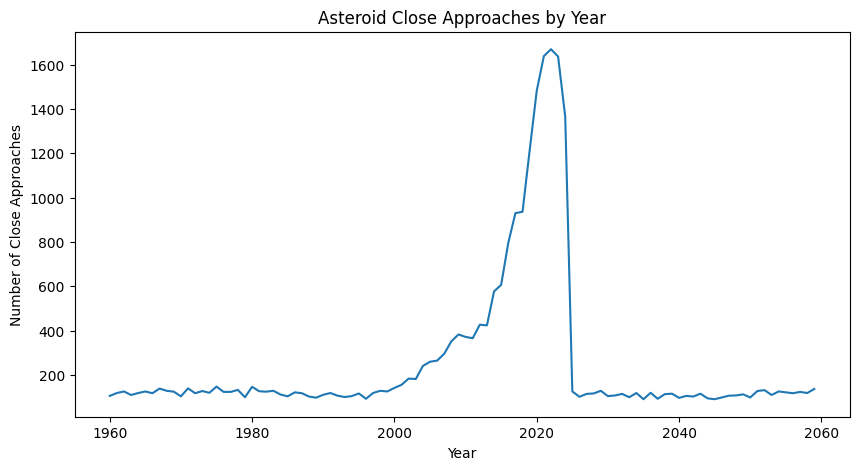

In [64]:
import matplotlib.pyplot as plt

yearly_pd = yearly_count.orderBy("Year").toPandas()

plt.figure(figsize=(10, 5))
plt.plot(yearly_pd["Year"], yearly_pd["Total Approaches"])

plt.xlabel("Year")
plt.ylabel("Number of Close Approaches")
plt.title("Asteroid Close Approaches by Year")

plt.show()

In [65]:
# finding how many recorded approaches fall within different distance ranges

from pyspark.sql.functions import when, col

distance_groups = asteroid_spark_df.withColumn(
    "Distance Range",
    when(col("dist") < 0.01, "Below 0.01 AU")
    .when(col("dist") < 0.05, "0.01 to 0.05 AU")
    .when(col("dist") < 0.1, "0.05 to 0.1 AU")
    .otherwise("0.1 AU and above")
)

distance_groups.groupBy("Distance Range").count().show()

+---------------+-----+
| Distance Range|count|
+---------------+-----+
|0.01 to 0.05 AU|20624|
|  Below 0.01 AU| 4962|
+---------------+-----+



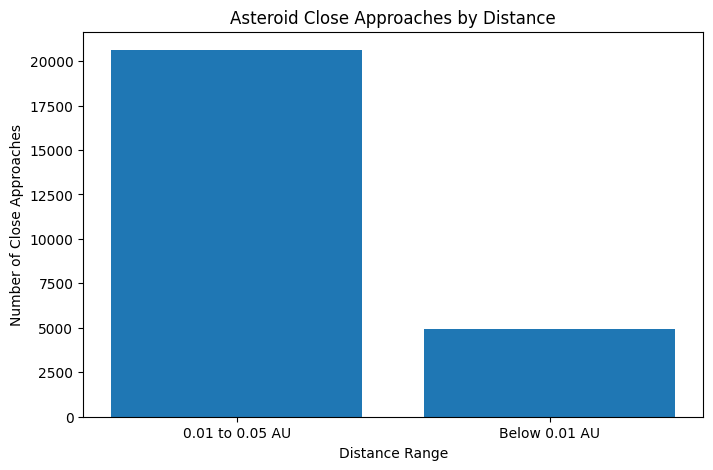

In [66]:
distance_pd = distance_groups.groupBy("Distance Range").count().toPandas()

plt.figure(figsize=(8, 5))
plt.bar(distance_pd["Distance Range"], distance_pd["count"])

plt.xlabel("Distance Range")
plt.ylabel("Number of Close Approaches")
plt.title("Asteroid Close Approaches by Distance")

plt.show()

In [67]:
# year with the smallest recorded approach distance

from pyspark.sql.functions import min

closest_by_year = asteroid_spark_df.groupBy(
    year("approach_date").alias("Year")
).agg(
    min("dist").alias("Closest Distance (AU)")
)

closest_by_year.orderBy("Year").show(10)

+----+---------------------+
|Year|Closest Distance (AU)|
+----+---------------------+
|1960|  0.00123030862494184|
|1961|  0.00236250983787484|
|1962|  0.00275669948162693|
|1963|   0.0076006805472253|
|1964|  0.00169545584374459|
|1965|  0.00227888881188568|
|1966|  0.00389213634202886|
|1967|  0.00337005421407267|
|1968|  6.12856576439748E-4|
|1969|  0.00266407646401608|
+----+---------------------+
only showing top 10 rows


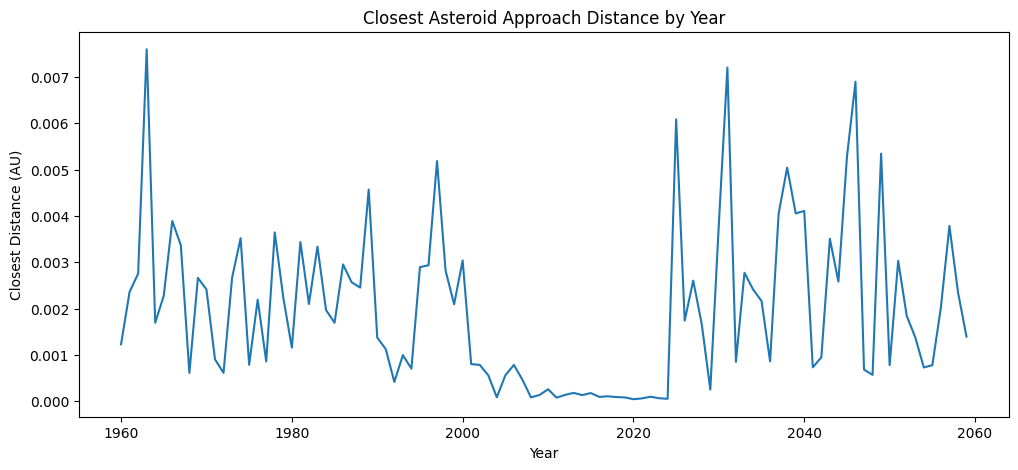

In [68]:
closest_pd = closest_by_year.orderBy("Year").toPandas()

plt.figure(figsize=(12, 5))
plt.plot(closest_pd["Year"], closest_pd["Closest Distance (AU)"])

plt.xlabel("Year")
plt.ylabel("Closest Distance (AU)")
plt.title("Closest Asteroid Approach Distance by Year")

plt.show()

In [69]:
asteroid_spark_df.orderBy("dist").select(
    "fullname", "cd", "dist", "v_rel"
).show(1, truncate=False)

+-----------------+-----------------+-------------------+----------------+
|fullname         |cd               |dist               |v_rel           |
+-----------------+-----------------+-------------------+----------------+
|       (2020 VT4)|2020-Nov-13 17:21|4.50910597356063E-5|13.4271195491719|
+-----------------+-----------------+-------------------+----------------+
only showing top 1 row


In [70]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, avg, count, year, to_timestamp, max as spark_max
)

# -------------------------------
# 1. Page setup
# -------------------------------

st.set_page_config(
    page_title="Asteroid Analysis",
    page_icon="☄️",
    layout="wide"
)

st.title("Near-Earth Asteroid Close-Approach Analysis")
st.write(
    "Explore NASA asteroid close-approach records using "
    "Apache Spark and interactive visualizations."
)

# -------------------------------
# 2. Start Spark and load data
# -------------------------------

@st.cache_resource
def create_spark():
    return (
        SparkSession.builder
        .appName("AsteroidAnalysisDashboard")
        .master("local[*]")
        .getOrCreate()
    )

spark = create_spark()

file_path = "/content/NASA_Close_Approach_Data_1960_2060.csv"

@st.cache_resource
def load_data(path):
    spark_session = create_spark()

    data = (
        spark_session.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(path)
    )

    data = (
        data
        .withColumn("dist", col("dist").cast("double"))
        .withColumn("v_rel", col("v_rel").cast("double"))
        .withColumn(
            "approach_date",
            to_timestamp("cd", "yyyy-MMM-dd HH:mm")
        )
        .withColumn("Year", year("approach_date"))
    )

    return data

try:
    df = load_data(file_path)
except Exception as e:
    st.error("Could not load the NASA dataset.")
    st.write("Check that the CSV file exists at:", file_path)
    st.code(str(e))
    st.stop()

# -------------------------------
# 3. Overall dataset information
# -------------------------------

total_records = df.count()

st.caption(f"Total records in the loaded dataset: {total_records:,}")

st.divider()

# -------------------------------
# 4. Interactive filters
# -------------------------------

st.subheader("🔎 Explore the Dataset")

valid_years = [
    int(row["Year"])
    for row in df.select("Year")
    .where(col("Year").isNotNull())
    .distinct()
    .orderBy("Year")
    .collect()
]

valid_distances = (
    df.where(col("dist").isNotNull())
    .select(spark_max("dist").alias("maximum"))
    .first()["maximum"]
)

if not valid_years or valid_distances is None:
    st.error("The dataset does not contain valid years or distances.")
    st.stop()

filter1, filter2 = st.columns(2)

with filter1:
    selected_year = st.selectbox(
        "Select approach year",
        options=["All years"] + valid_years
    )

with filter2:
    max_distance = st.slider(
        "Maximum approach distance (AU)",
        min_value=0.001,
        max_value=max(0.1, min(float(valid_distances), 10.0)),
        value=0.1,
        step=0.001,
        help="Show approaches at or below the selected distance."
    )

filtered_df = df.filter(
    col("dist").isNotNull() &
    (col("dist") <= max_distance)
)

if selected_year != "All years":
    filtered_df = filtered_df.filter(
        col("Year") == selected_year
    )

# -------------------------------
# 5. Summary metric cards
# -------------------------------

summary = filtered_df.agg(
    count("*").alias("total"),
    avg("dist").alias("avg_dist"),
    avg("v_rel").alias("avg_velocity")
).first()

filtered_count = summary["total"]
average_distance = summary["avg_dist"]
average_velocity = summary["avg_velocity"]

st.subheader("📊 Summary of Selected Records")

m1, m2, m3 = st.columns(3)

m1.metric("Matching Approaches", f"{filtered_count:,}")
m2.metric(
    "Average Distance (AU)",
    f"{average_distance:.6f}" if average_distance is not None else "N/A"
)
m3.metric(
    "Average Velocity (km/s)",
    f"{average_velocity:.2f}" if average_velocity is not None else "N/A"
)

if filtered_count == 0:
    st.warning("No records match these filters. Try a larger distance or another year.")
    st.stop()

# -------------------------------
# 6. Closest approaches table
# -------------------------------

st.divider()
st.subheader("🌍 Closest Recorded Approaches")

closest_pd = (
    filtered_df
    .orderBy("dist")
    .select("fullname", "cd", "dist", "v_rel")
    .limit(10)
    .toPandas()
)

closest_pd.columns = [
    "Asteroid", "Approach Date", "Distance (AU)", "Velocity (km/s)"
]

st.dataframe(closest_pd, use_container_width=True)

# -------------------------------
# 7. Year-wise approach chart
# -------------------------------

st.divider()
st.subheader("📅 Asteroid Approaches by Year")

yearly_pd = (
    filtered_df
    .filter(col("Year").isNotNull())
    .groupBy("Year")
    .agg(count("*").alias("Total Approaches"))
    .orderBy("Year")
    .toPandas()
)

if not yearly_pd.empty:
    fig1 = px.line(
        yearly_pd,
        x="Year",
        y="Total Approaches",
        markers=True,
        title="Number of Approaches by Year"
    )
    st.plotly_chart(fig1, use_container_width=True)

# -------------------------------
# 8. Distance range chart
# -------------------------------

st.subheader("Approaches by Distance Range")

distance_pd = filtered_df.select("dist").toPandas().dropna()

if not distance_pd.empty:
    distance_pd["Distance Range"] = pd.cut(
        distance_pd["dist"],
        bins=[-float("inf"), 0.01, 0.05, 0.1, float("inf")],
        labels=[
            "Below 0.01 AU",
            "0.01–0.05 AU",
            "0.05–0.1 AU",
            "0.1 AU and above"
        ],
        right=False
    )

    range_counts = (
        distance_pd["Distance Range"]
        .value_counts(sort=False)
        .rename_axis("Distance Range")
        .reset_index(name="Count")
    )

    fig2 = px.bar(
        range_counts,
        x="Distance Range",
        y="Count",
        title="Number of Approaches in Each Distance Range"
    )
    st.plotly_chart(fig2, use_container_width=True)

# -------------------------------
# 9. Distance versus velocity
# -------------------------------

st.divider()
st.subheader(" Distance vs. Relative Velocity")

scatter_pd = (
    filtered_df
    .filter(col("v_rel").isNotNull())
    .select("fullname", "dist", "v_rel")
    .limit(5000)
    .toPandas()
)

if not scatter_pd.empty:
    fig3 = px.scatter(
        scatter_pd,
        x="dist",
        y="v_rel",
        hover_name="fullname",
        labels={
            "dist": "Approach Distance (AU)",
            "v_rel": "Relative Velocity (km/s)"
        },
        title="Approach Distance Compared with Relative Velocity"
    )
    st.plotly_chart(fig3, use_container_width=True)
    st.caption("The scatter plot displays up to 5,000 matching records.")
else:
    st.info("No valid velocity records are available for this chart.")

# -------------------------------
# 10. Automatic findings
# -------------------------------

st.divider()
st.subheader("💡 Key Findings from the Full Dataset")

global_yearly = (
    df.filter(col("Year").isNotNull())
    .groupBy("Year")
    .agg(count("*").alias("Total Approaches"))
    .orderBy(col("Total Approaches").desc(), col("Year").asc())
    .first()
)

global_closest = (
    df.filter(col("dist").isNotNull())
    .orderBy("dist")
    .select("fullname", "cd", "dist", "v_rel")
    .first()
)

global_fastest = (
    df.filter(col("v_rel").isNotNull())
    .orderBy(col("v_rel").desc())
    .select("fullname", "cd", "dist", "v_rel")
    .first()
)

if global_yearly:
    st.write(
        f"**Year with the most recorded approaches:** "
        f"{global_yearly['Year']} "
        f"({global_yearly['Total Approaches']:,} records)."
    )

if global_closest:
    st.write(
        f"**Closest recorded approach:** "
        f"{global_closest['fullname']} on {global_closest['cd']}, "
        f"at {global_closest['dist']:.8f} AU."
    )

if global_fastest:
    st.write(
        f"**Fastest recorded approach:** "
        f"{global_fastest['fullname']} on {global_fastest['cd']}, "
        f"at {global_fastest['v_rel']:.2f} km/s."
    )

st.caption(
    "These are statistics from the supplied dataset, not predictions "
    "of future asteroid impacts."
)

# -------------------------------
# 11. Download filtered records
# -------------------------------

st.divider()
st.subheader("⬇️ Download Selected Data")

download_pd = (
    filtered_df
    .select("fullname", "cd", "dist", "v_rel", "Year")
    .toPandas()
)

csv_data = download_pd.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download Filtered Records as CSV",
    data=csv_data,
    file_name="filtered_asteroid_approaches.csv",
    mime="text/csv"
)

st.caption("Data processing: Apache Spark | Dashboard: Streamlit | Charts: Plotly")

Overwriting app.py


In [71]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

(Reading database ... 122811 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.10.3) over (2026.10.3) ...
Setting up cloudflared (2026.10.3) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [72]:
!cloudflared --version

cloudflared version 2026.10.3 (built 2026-10-21-13:11 UTC)


In [73]:
!pip install -q streamlit plotly

In [74]:
!pkill -f streamlit || true

^C


In [75]:
!streamlit run /content/app.py --server.address 0.0.0.0 --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [76]:
import time
time.sleep(5)

!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Wed, 21 Oct 2026 15:22:27 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Wed, 21 Oct 2026 15:12:18 GMT
etag: "f9ff7590290a103a295bd0a08140819d"
cache-control: no-cache



In [77]:
!cloudflared tunnel --url http://127.0.0.1:8501

2026-10-21T15:22:28Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-21T15:22:28Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-21T15:22:31Z INF +--------------------------------------------------------------------------------------------+
2026-10-21T15:22:31Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-21T15:22:31Z INF |  https://tucson-affordable-utah-head.trycloudflare.com